# 🎬 Análise de Filmes / IMDb

**Disciplina:** Tópicos de Big Data em Python  
**Objetivo:** carregar, tratar, analisar e visualizar dados de filmes usando **Pandas, Matplotlib e Seaborn**.

> O programa analisa filmes, gênero dos filmes, anos, notas e votos!

## Perguntas que o projeto investiga
- Quais gêneros aparecem com mais frequência nos filmes de 1980 em diante?
- Quais gêneros têm as maiores notas médias entre filmes? (com um número mínimo de votos)
- Como a quantidade de filmes cadastrados e as notas médias variam ao longo dos anos?
- Como a nota se relaciona com a quantidade de votos?
- Quais filmes combinam nota alta com um número de votos?

**Fonte:** conjuntos de dados públicos da IMDb: [title.basics.tsv.gz](https://datasets.imdbws.com/title.basics.tsv.gz) e [title.ratings.tsv.gz](https://datasets.imdbws.com/title.ratings.tsv.gz). No IMDb, voto é a ação individual do usuário, enquanto nota é o resultado público calculado pelo site. Não representam exclusivamente críticas profissionais.



## 1. Preparar o ambiente

In [ ]:
%pip -q install pandas numpy matplotlib seaborn requests

import os
import html
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, HTML
from pathlib import Path

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (12, 5)

print("Ambiente preparado com sucesso!")

Ambiente preparado com sucesso!


## 2. Baixar os arquivos disponiveis online

In [ ]:
URL_FILMES = "https://datasets.imdbws.com/title.basics.tsv.gz"
URL_NOTAS = "https://datasets.imdbws.com/title.ratings.tsv.gz"


def baixar_arquivo(url: str, destino: str) -> None:
    caminho = Path(destino)
    if caminho.exists() and caminho.stat().st_size > 0:
        print(f"Arquivo já existe: {destino}")
        return

    print(f"Baixando {destino}...")
    with requests.get(url, stream=True, timeout=(20, 180)) as resposta:
        resposta.raise_for_status()
        with open(caminho, "wb") as arquivo:
            for bloco in resposta.iter_content(chunk_size=1024 * 1024):
                if bloco:
                    arquivo.write(bloco)
    print(f"Download concluído: {destino}")


baixar_arquivo(URL_FILMES, "title.basics.tsv.gz")
baixar_arquivo(URL_NOTAS, "title.ratings.tsv.gz")

Arquivo já existe: title.basics.tsv.gz
Arquivo já existe: title.ratings.tsv.gz


## 3. Ler e filtrar os dados com Pandas

In [ ]:
COLUNAS_FILMES = ["tconst", "titleType", "primaryTitle", "startYear", "genres"]
ANO_INICIAL = 1980
ANO_ATUAL = pd.Timestamp.now().year
TAMANHO_BLOCO = 300_000

partes_filmes = []

leitor = pd.read_csv(
    "title.basics.tsv.gz",
    sep="\t",
    compression="gzip",
    usecols=COLUNAS_FILMES,
    na_values=["\\N"],
    dtype={
        "tconst": "string",
        "titleType": "string",
        "primaryTitle": "string",
        "startYear": "string",
        "genres": "string",
    },
    chunksize=TAMANHO_BLOCO,
    low_memory=False,
)

for numero_bloco, bloco in enumerate(leitor, start=1):
    bloco["startYear"] = pd.to_numeric(bloco["startYear"], errors="coerce")

    filtro = (
        (bloco["titleType"] == "movie")
        & (bloco["startYear"] >= ANO_INICIAL)
        & (bloco["startYear"] <= ANO_ATUAL)
        & bloco["primaryTitle"].notna()
        & bloco["genres"].notna()
    )
    partes_filmes.append(bloco.loc[filtro, COLUNAS_FILMES].copy())
    if numero_bloco % 5 == 0:
        print(f"Blocos processados: {numero_bloco}")

if not partes_filmes:
    raise ValueError("Nenhum filme foi encontrado.")

filmes = pd.concat(partes_filmes, ignore_index=True)
del partes_filmes, leitor
filmes = filmes.drop_duplicates(subset="tconst")
filmes["startYear"] = filmes["startYear"].astype("int16")

print(f"Filmes após filtragem: {len(filmes):,}")
display(filmes.head())

Blocos processados: 5
Blocos processados: 10
Blocos processados: 15
Blocos processados: 20
Blocos processados: 25
Blocos processados: 30
Blocos processados: 35
Blocos processados: 40
Filmes após filtragem: 443,836


,tconst,titleType,primaryTitle,startYear,genres
0,tt0011801,movie,Tötet nicht mehr,2019,"Action,Crime"
1,tt0015724,movie,Dama de noche,1993,"Drama,Mystery,Romance"
2,tt0035423,movie,Kate & Leopold,2001,"Comedy,Fantasy,Romance"
3,tt0036606,movie,"Another Time, Another Place",1983,"Drama,War"
4,tt0038086,movie,Shiva und die Galgenblume,1993,"Documentary,Thriller"


## 4. Carregar as notas e juntar as tabelas

In [ ]:
notas = pd.read_csv(
    "title.ratings.tsv.gz",
    sep="\t",
    compression="gzip",
    usecols=["tconst", "averageRating", "numVotes"],
    dtype={"tconst": "string"},
    na_values=["\\N"],
    low_memory=False,
)

notas["averageRating"] = pd.to_numeric(notas["averageRating"], errors="coerce")
notas["numVotes"] = pd.to_numeric(notas["numVotes"], errors="coerce")

df = filmes.merge(notas, on="tconst", how="inner", validate="one_to_one")
df = df.dropna(subset=["primaryTitle", "startYear", "genres", "averageRating", "numVotes"])
df = df.drop_duplicates(subset="tconst").copy()
df["startYear"] = df["startYear"].astype("int16")
df["numVotes"] = df["numVotes"].astype("int64")
df["averageRating"] = df["averageRating"].astype("float32")

print("Tabelas unidas com sucesso!")
print(f"Total de filmes analisados: {len(df):,}")
print(f"Período: {df['startYear'].min()}–{df['startYear'].max()}")
display(df[["primaryTitle", "startYear", "genres", "averageRating", "numVotes"]].head(10))

Tabelas unidas com sucesso!
Total de filmes analisados: 262,473
Período: 1980–2026


,primaryTitle,startYear,genres,averageRating,numVotes
0,Dama de noche,1993,"Drama,Mystery,Romance",6.2,35
1,Kate & Leopold,2001,"Comedy,Fantasy,Romance",6.4,95002
2,"Another Time, Another Place",1983,"Drama,War",6.4,388
3,Shiva und die Galgenblume,1993,"Documentary,Thriller",7.0,26
4,Rendez-vous of the Docks,1990,Drama,6.6,76
5,La rosa de los vientos,1983,"Drama,Fantasy",4.7,29
6,Just Don't Think I'll Cry,1990,Drama,6.6,74
7,Born in '45,1990,"Drama,Romance",6.5,300
8,"Wenn du groß bist, lieber Adam",1990,"Drama,Fantasy",6.4,49
9,Hands Up!,1981,Drama,6.5,520


## 5. Verificar tudo

In [ ]:
print("Informações da base:")
df.info()

print("\nValores ausentes por coluna:")
display(df.isna().sum().to_frame("valores_ausentes"))

print("\nQuantidade de IDs duplicados:", int(df["tconst"].duplicated().sum()))
print("\nEstatísticas das notas e votos:")
display(df[["averageRating", "numVotes", "startYear"]].describe().round(2))

Informações da base:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 262473 entries, 0 to 262472
Data columns (total 7 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   tconst         262473 non-null  string 
 1   titleType      262473 non-null  string 
 2   primaryTitle   262473 non-null  string 
 3   startYear      262473 non-null  int16  
 4   genres         262473 non-null  string 
 5   averageRating  262473 non-null  float32
 6   numVotes       262473 non-null  int64  
dtypes: float32(1), int16(1), int64(1), string(4)
memory usage: 11.5 MB

Valores ausentes por coluna:


,valores_ausentes
tconst,0
titleType,0
primaryTitle,0
startYear,0
genres,0
averageRating,0
numVotes,0



Quantidade de IDs duplicados: 0

Estatísticas das notas e votos:


,averageRating,numVotes,startYear
count,262473.00,262473.00,262473.00
mean,6.19,4547.48,2010.39
std,1.45,42882.21,12.16
min,1.00,5.00,1980.00
25%,5.30,22.00,2004.00
50%,6.30,73.00,2014.00
75%,7.20,383.00,2020.00
max,10.00,3255716.00,2026.00


## 6. Indicadores principais do dashboard

In [ ]:
nota_media_geral = df["averageRating"].mean()
nota_mediana = df["averageRating"].median()
filme_mais_votado = df.loc[df["numVotes"].idxmax()]
quantidade_anos = df["startYear"].nunique()

html_indicadores = f'''<div style="display:flex;flex-wrap:wrap;gap:14px;background:#101010;padding:20px;border-radius:16px;color:#f5f5f5;font-family:Arial,sans-serif;">
  <div style="flex:1;min-width:170px;background:#1b1b1b;border:1px solid #8c7022;border-radius:12px;padding:16px;">
    <div style="color:#bbbbbb;font-size:13px;">Filmes analisados</div>
    <div style="color:#D4AF37;font-size:28px;font-weight:bold;">{len(df):,}</div>
  </div>
  <div style="flex:1;min-width:170px;background:#1b1b1b;border:1px solid #8c7022;border-radius:12px;padding:16px;">
    <div style="color:#bbbbbb;font-size:13px;">Nota média</div>
    <div style="color:#D4AF37;font-size:28px;font-weight:bold;">{nota_media_geral:.2f}/10</div>
  </div>
  <div style="flex:1;min-width:170px;background:#1b1b1b;border:1px solid #8c7022;border-radius:12px;padding:16px;">
    <div style="color:#bbbbbb;font-size:13px;">Nota mediana</div>
    <div style="color:#D4AF37;font-size:28px;font-weight:bold;">{nota_mediana:.2f}/10</div>
  </div>
  <div style="flex:1;min-width:170px;background:#1b1b1b;border:1px solid #8c7022;border-radius:12px;padding:16px;">
    <div style="color:#bbbbbb;font-size:13px;">Anos no recorte</div>
    <div style="color:#D4AF37;font-size:28px;font-weight:bold;">{quantidade_anos}</div>
  </div>
</div>'''
display(HTML(html_indicadores))

print("Filme com mais votos na base filtrada:")
print(f"{filme_mais_votado['primaryTitle']} ({filme_mais_votado['startYear']}) — "
      f"nota {filme_mais_votado['averageRating']:.1f}/10, "
      f"{filme_mais_votado['numVotes']:,} votos")

Filme com mais votos na base filtrada:
The Shawshank Redemption (1994) — nota 9.3/10, 3,255,716 votos


## 7. Filmes por ano de lançamento

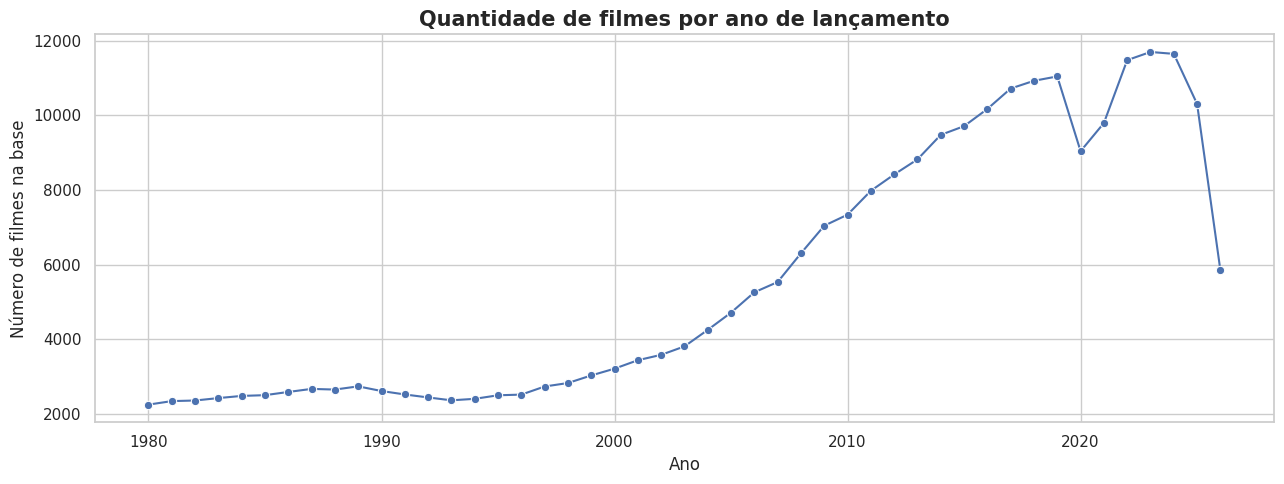

In [ ]:
filmes_por_ano = (
    df.groupby("startYear")
      .size()
      .reset_index(name="quantidade_filmes")
)

plt.figure(figsize=(13, 5))
sns.lineplot(data=filmes_por_ano, x="startYear", y="quantidade_filmes", marker="o")
plt.title("Quantidade de filmes por ano de lançamento", fontsize=15, weight="bold")
plt.xlabel("Ano")
plt.ylabel("Número de filmes na base")
plt.tight_layout()
plt.show()

## 8. Como a nota média varia por ano?

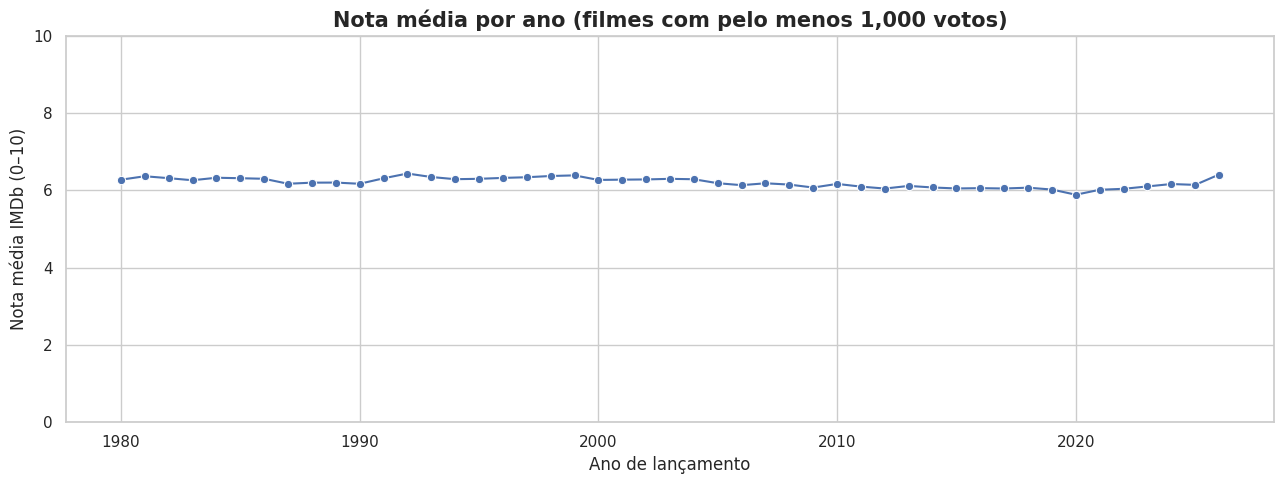

,startYear,nota_media,quantidade_filmes
37,2017,6.05,1662
38,2018,6.07,1703
39,2019,6.02,1739
40,2020,5.89,1323
41,2021,6.02,1484
42,2022,6.04,1777
43,2023,6.10,1717
44,2024,6.16,1602
45,2025,6.14,1305
46,2026,6.41,735


In [ ]:
MIN_VOTOS_ANALISE = 1_000
base_popular = df.loc[df["numVotes"] >= MIN_VOTOS_ANALISE].copy()

notas_por_ano = (
    base_popular.groupby("startYear")
    .agg(nota_media=("averageRating", "mean"), quantidade_filmes=("tconst", "nunique"))
    .reset_index()
)

plt.figure(figsize=(13, 5))
sns.lineplot(data=notas_por_ano, x="startYear", y="nota_media", marker="o")
plt.title(f"Nota média por ano (filmes com pelo menos {MIN_VOTOS_ANALISE:,} votos)", fontsize=15, weight="bold")
plt.xlabel("Ano de lançamento")
plt.ylabel("Nota média IMDb (0–10)")
plt.ylim(0, 10)
plt.tight_layout()
plt.show()

display(notas_por_ano.tail(10).round(2))

## 9. Quais gêneros aparecem mais?

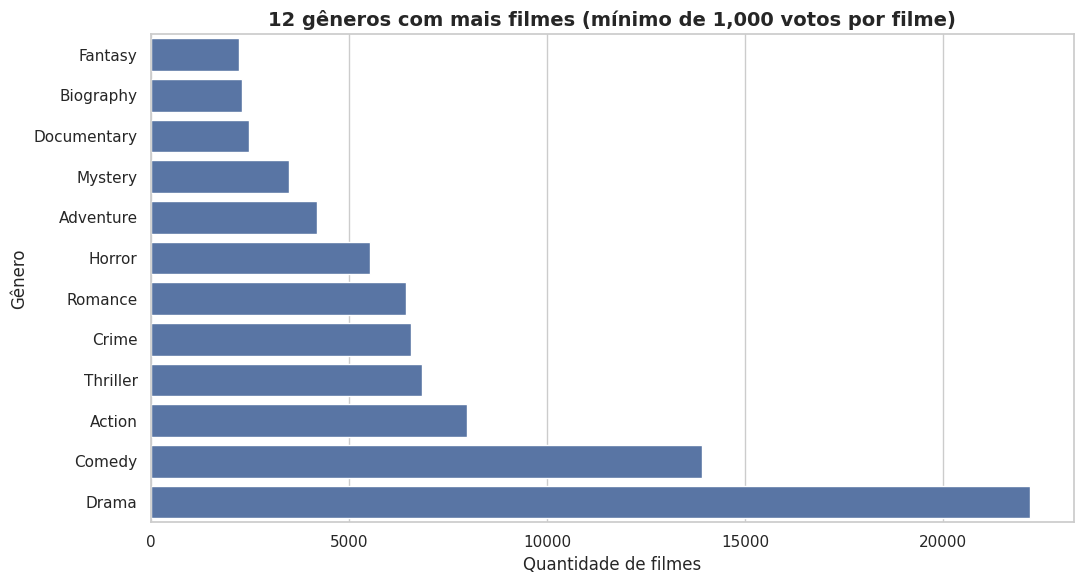

,genero,quantidade_filmes,nota_media,nota_mediana
8,Drama,22185,6.41,6.5
5,Comedy,13901,6.06,6.2
0,Action,7985,5.87,6.0
21,Thriller,6839,5.75,5.8
6,Crime,6556,6.21,6.3
17,Romance,6432,6.27,6.4
12,Horror,5532,5.15,5.2
2,Adventure,4195,6.02,6.2
15,Mystery,3488,5.86,5.9
7,Documentary,2473,7.18,7.3


In [ ]:
generos_longos = (
    base_popular.assign(genero=base_popular["genres"].str.split(","))
    .explode("genero")
)

generos_stats = (
    generos_longos.groupby("genero")
    .agg(
        quantidade_filmes=("tconst", "nunique"),
        nota_media=("averageRating", "mean"),
        nota_mediana=("averageRating", "median"),
    )
    .reset_index()
)

top_generos_quantidade = generos_stats.nlargest(12, "quantidade_filmes").sort_values("quantidade_filmes")

plt.figure(figsize=(11, 6))
sns.barplot(data=top_generos_quantidade, x="quantidade_filmes", y="genero")
plt.title(f"12 gêneros com mais filmes (mínimo de {MIN_VOTOS_ANALISE:,} votos por filme)", fontsize=14, weight="bold")
plt.xlabel("Quantidade de filmes")
plt.ylabel("Gênero")
plt.tight_layout()
plt.show()

display(generos_stats.sort_values("quantidade_filmes", ascending=False).head(12).round(2))

## 10. Quais gêneros tem as maiores notas medias?

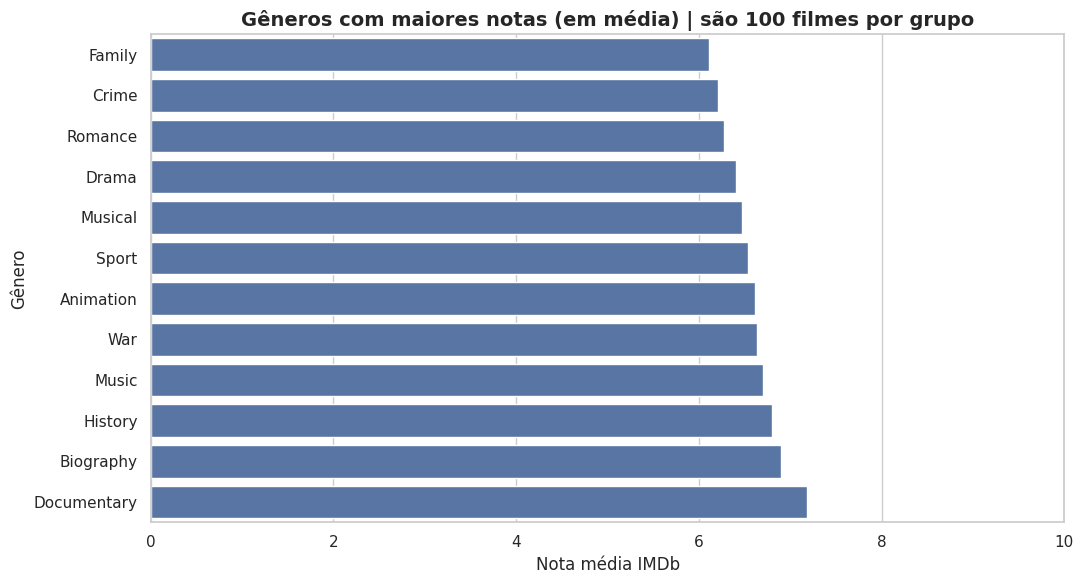

,genero,quantidade_filmes,nota_media,nota_mediana
7,Documentary,2473,7.18,7.3
4,Biography,2304,6.90,7.0
11,History,1565,6.80,6.9
13,Music,1284,6.70,6.8
22,War,732,6.63,6.8
3,Animation,1538,6.61,6.8
19,Sport,827,6.54,6.7
14,Musical,463,6.48,6.6
8,Drama,22185,6.41,6.5
17,Romance,6432,6.27,6.4


In [ ]:
MIN_FILMES_POR_GENERO = 100
ranking_notas_generos = (
    generos_stats.loc[generos_stats["quantidade_filmes"] >= MIN_FILMES_POR_GENERO]
    .sort_values("nota_media", ascending=False)
)

melhores_generos = ranking_notas_generos.head(12).sort_values("nota_media")

plt.figure(figsize=(11, 6))
sns.barplot(data=melhores_generos, x="nota_media", y="genero")
plt.title(f"Gêneros com maiores notas (em média) | são {MIN_FILMES_POR_GENERO} filmes por grupo", fontsize=14, weight="bold")
plt.xlabel("Nota média IMDb")
plt.ylabel("Gênero")
plt.xlim(0, 10)
plt.tight_layout()
plt.show()

display(ranking_notas_generos.head(12).round(2))

## 11. Distribuição das notas

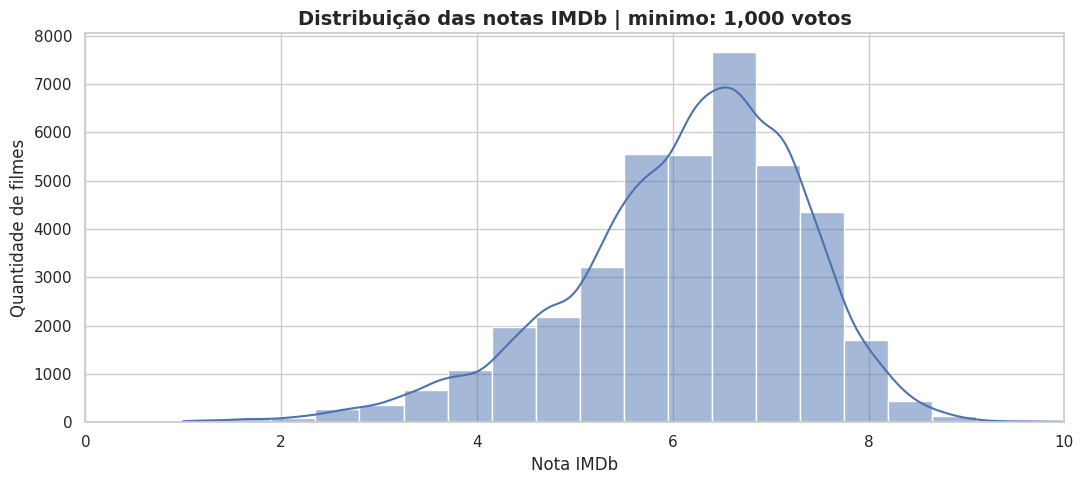

In [ ]:
plt.figure(figsize=(11, 5))
sns.histplot(data=base_popular, x="averageRating", bins=20, kde=True)
plt.title(f"Distribuição das notas IMDb | minimo: {MIN_VOTOS_ANALISE:,} votos", fontsize=14, weight="bold")
plt.xlabel("Nota IMDb")
plt.ylabel("Quantidade de filmes")
plt.xlim(0, 10)
plt.tight_layout()
plt.show()

## 12. Relação entre quantidade de votos e nota

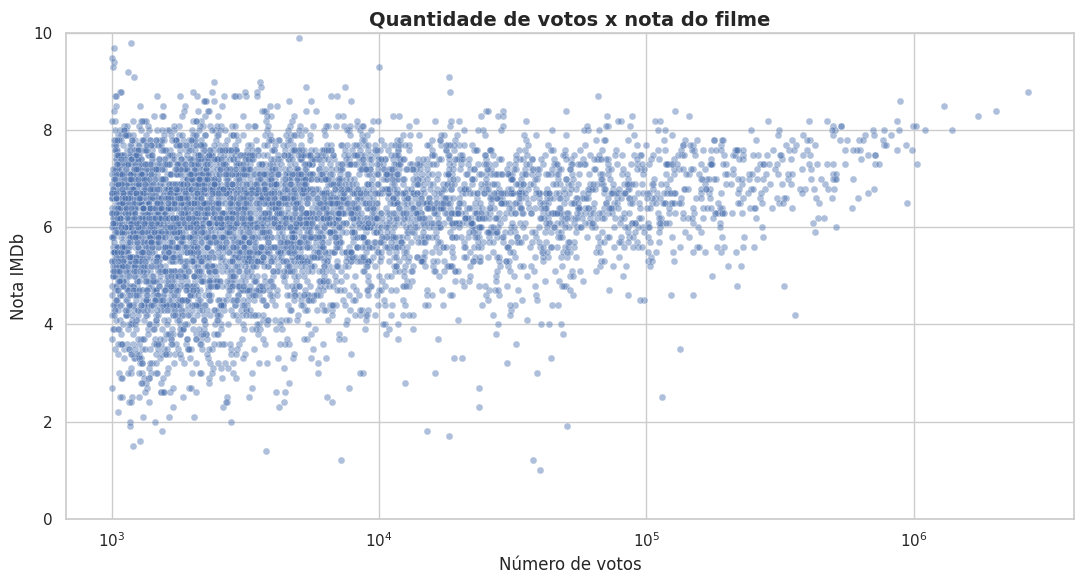

In [ ]:
quantidade_amostra = min(6_000, len(base_popular))
amostra = base_popular.sample(n=quantidade_amostra, random_state=42) if quantidade_amostra else base_popular

plt.figure(figsize=(11, 6))
sns.scatterplot(data=amostra, x="numVotes", y="averageRating", alpha=0.45, s=25)
plt.xscale("log")
plt.title("Quantidade de votos x nota do filme", fontsize=14, weight="bold")
plt.xlabel("Número de votos")
plt.ylabel("Nota IMDb")
plt.ylim(0, 10)
plt.tight_layout()
plt.show()

## 13. Filmes em destaque

In [ ]:
MIN_VOTOS_DESTAQUE = 10_000

destaques = (
    df.loc[df["numVotes"] >= MIN_VOTOS_DESTAQUE]
      .sort_values(["averageRating", "numVotes"], ascending=[False, False])
      .head(8)
)

if destaques.empty:
    print("Nenhum filme alcançou o limite de votos definido para os destaques.")
else:
    cards = ""
    for _, filme in destaques.iterrows():
        titulo = html.escape(str(filme["primaryTitle"]))
        ano = int(filme["startYear"])
        nota = float(filme["averageRating"])
        votos = int(filme["numVotes"])
        imdb_id = html.escape(str(filme["tconst"]))
        cards += f'''        <div style="background:#1b1b1b;border:1px solid #8c7022;border-radius:12px;padding:16px;width:220px;box-sizing:border-box;color:#f5f5f5;font-family:Arial,sans-serif;">
          <div style="height:95px;border-radius:8px;background:linear-gradient(145deg,#292929,#111111);display:flex;align-items:center;justify-content:center;color:#D4AF37;font-size:38px;">🎬</div>
          <h3 style="color:#D4AF37;font-size:16px;margin:12px 0 8px;">{titulo}</h3>
          <p style="margin:5px 0;">Ano: {ano}</p>
          <p style="margin:5px 0;">Nota IMDb: {nota:.1f}/10</p>
          <p style="margin:5px 0;">Votos: {votos:,}</p>
          <a href="https://www.imdb.com/title/{imdb_id}/" target="_blank" rel="noopener noreferrer" style="color:#D4AF37;">Ver na IMDb ↗</a>
        </div>'''

    display(HTML(f'''    <div style="background:#101010;padding:24px;border-radius:16px;color:white;font-family:Arial,sans-serif;">
      <h2 style="color:#D4AF37;margin-top:0;">FILMES EM DESTAQUE</h2>
      <p style="color:#bbbbbb;">Filmes com nota alta e pelo menos {MIN_VOTOS_DESTAQUE:,} votos. A seleção é recalculada a partir do arquivo atual.</p>
      <div style="display:flex;flex-wrap:wrap;gap:16px;">{cards}</div>
    </div>'''))


## 14. Resumo dos dados

In [ ]:
if not generos_stats.empty:
    genero_mais_frequente = generos_stats.loc[generos_stats["quantidade_filmes"].idxmax()]
    print(f"Gênero mais frequente entre os filmes analisados: "
          f"{genero_mais_frequente['genero']} ({int(genero_mais_frequente['quantidade_filmes']):,} filmes).")

if not ranking_notas_generos.empty:
    genero_melhor_nota = ranking_notas_generos.iloc[0]
    print(f"Maior nota média entre os gêneros de filme: "
          f"{genero_melhor_nota['genero']} ({genero_melhor_nota['nota_media']:.2f}/10).")

print(f"Nota média de todos os filmes: {df['averageRating'].mean():.2f}/10.")
print(f"Período dos filmes analisados: {df['startYear'].min()}–{df['startYear'].max()}.")

Gênero mais frequente entre os filmes analisados: Drama (22,185 filmes).
Maior nota média entre os gêneros de filme: Documentary (7.18/10).
Nota média de todos os filmes: 6.19/10.
Período dos filmes analisados: 1980–2026.
